# Pan-India Groundwater & Hydro-Climatic EDA
### B.Tech Project (CE4198P, IIT Guwahati)
---

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 120

catalog_path = r"../dataset/stations_master.parquet"
summary_path = r"../dataset/state_coverage_summary.csv"

stations_df = pd.read_parquet(catalog_path)
summary_df = pd.read_csv(summary_path)
print(f"✅ Successfully loaded Master Catalog: {len(stations_df):,} stations across India!")


✅ Successfully loaded Master Catalog: 6,979 stations across India!


## 1. Physical Stations Overview by Category

,category,total_stations,avg_records,avg_missing_pct
0,gwl,4719,2756,0.00
1,humidity,239,24636,0.00
2,pressure,256,17318,0.00
3,rainfall,825,3510,23.43
4,rwl,336,35768,0.89
5,solar_radiation,405,23677,0.00
6,temperature,199,21380,0.00


C:\Users\ASUS\AppData\Local\Temp\ipykernel_14360\3422528571.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=cat_summary, x="category", y="total_stations", palette="viridis")


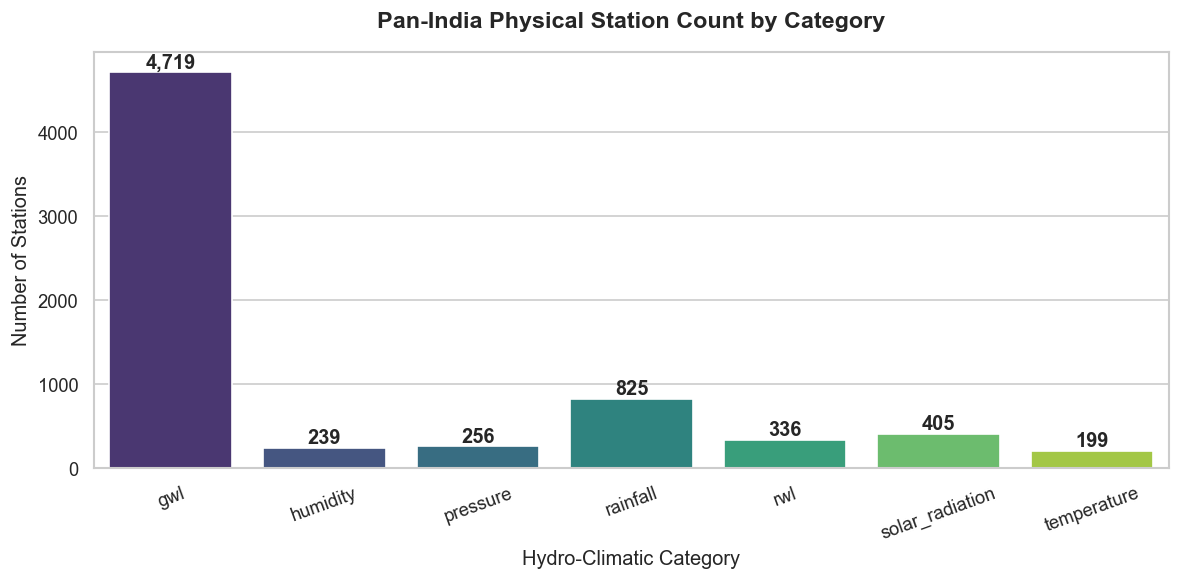

In [2]:
cat_summary = stations_df.groupby("category").agg(
    total_stations=("station_id", "count"),
    avg_records=("total_records", lambda x: int(x.mean())),
    avg_missing_pct=("missing_percent", lambda x: round(x.mean(), 2))
).reset_index()

display(cat_summary)

# Bar Chart: Physical Stations per Category
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=cat_summary, x="category", y="total_stations", palette="viridis")
plt.title("Pan-India Physical Station Count by Category", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Hydro-Climatic Category", fontsize=12)
plt.ylabel("Number of Stations", fontsize=12)
plt.xticks(rotation=20)

for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontweight="bold")

plt.tight_layout()
plt.show()


## 2. Top 15 States by Groundwater Well Density & Quality

C:\Users\ASUS\AppData\Local\Temp\ipykernel_14360\33190315.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top15_df, x="gwl", y="state", palette="Blues_r")


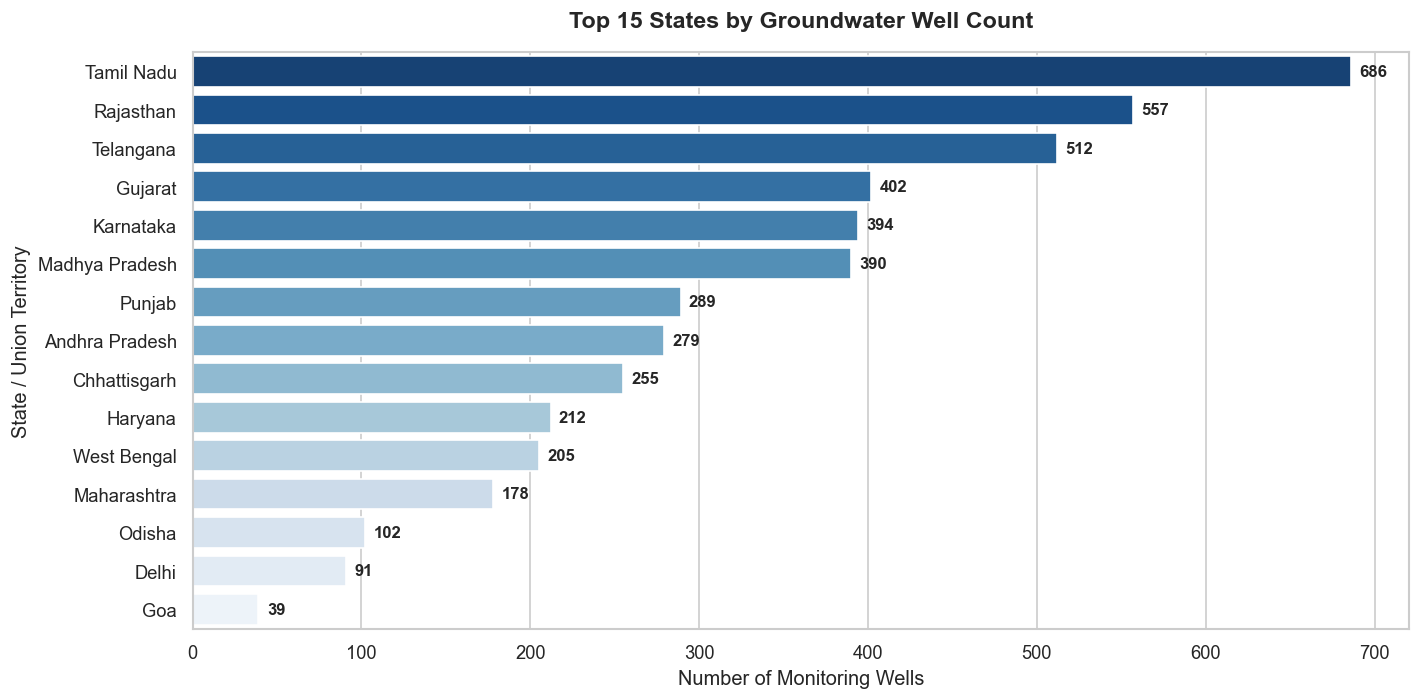

In [3]:
top15_df = summary_df.head(15)

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=top15_df, x="gwl", y="state", palette="Blues_r")
plt.title("Top 15 States by Groundwater Well Count", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Number of Monitoring Wells", fontsize=12)
plt.ylabel("State / Union Territory", fontsize=12)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{int(width):,}", (width + 5, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()


## 3. Spatial Map: Pan-India Station Coordinates Distribution

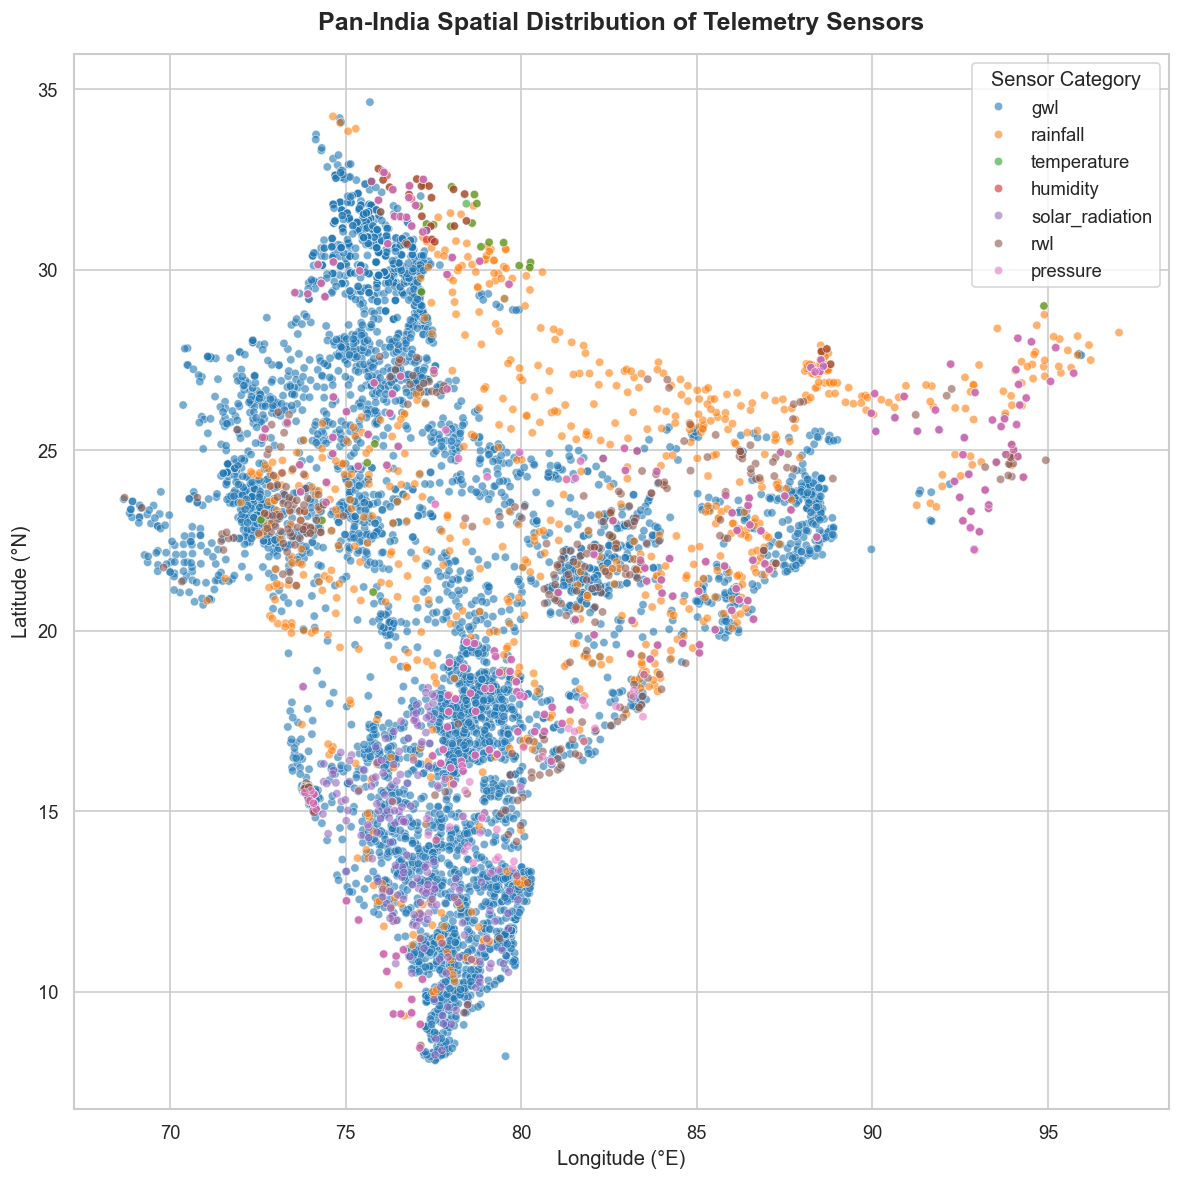

In [4]:
# Filter valid coordinates
valid_geo = stations_df.dropna(subset=["latitude", "longitude"])
valid_geo = valid_geo[(valid_geo["latitude"] >= 6.0) & (valid_geo["latitude"] <= 38.0) &
                      (valid_geo["longitude"] >= 68.0) & (valid_geo["longitude"] <= 98.0)]

plt.figure(figsize=(10, 10))
sns.scatterplot(
    data=valid_geo,
    x="longitude",
    y="latitude",
    hue="category",
    alpha=0.6,
    s=25,
    palette="tab10"
)
plt.title("Pan-India Spatial Distribution of Telemetry Sensors", fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Longitude (°E)", fontsize=12)
plt.ylabel("Latitude (°N)", fontsize=12)
plt.legend(title="Sensor Category", loc="upper right", frameon=True)
plt.tight_layout()
plt.show()


## 4. Sample Groundwater Level Time-Series Inspection

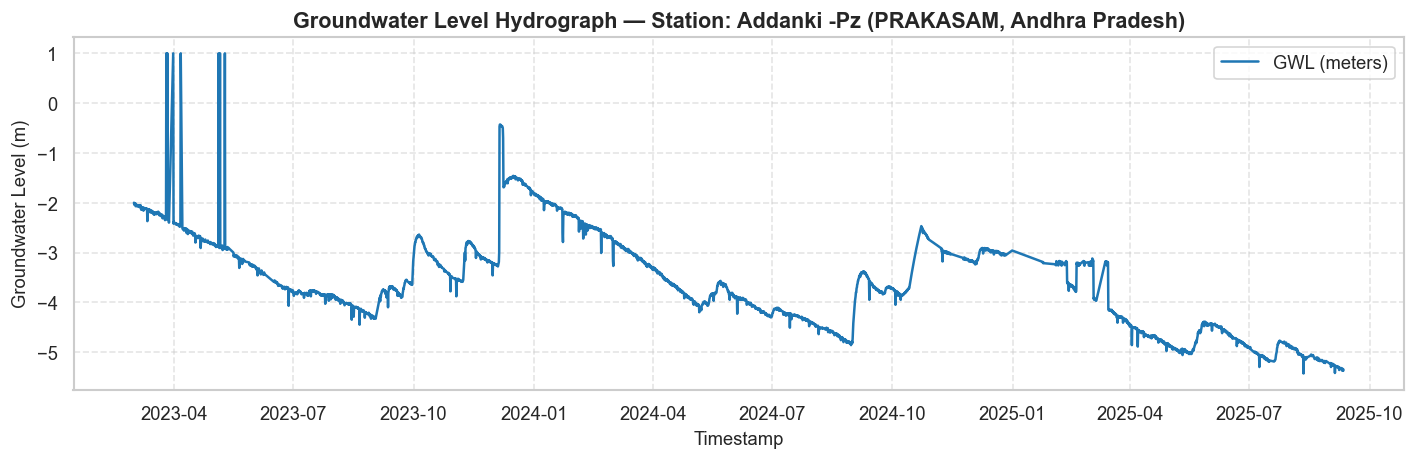

In [5]:
# Load sample GWL file (Andhra Pradesh)
gw_sample_path = r"../dataset/parquet/gwl/clean_gwl_tel_6_hourly_cgwb_ap_2021_2025.parquet"
gw_df = pd.read_parquet(gw_sample_path)

# Select first station
sample_station = gw_df["station_name"].iloc[0]
st_data = gw_df[gw_df["station_name"] == sample_station].sort_values("timestamp")

plt.figure(figsize=(12, 4))
plt.plot(st_data["timestamp"], st_data["gwl_m"], color="#1f77b4", linewidth=1.5, label="GWL (meters)")
plt.title(f"Groundwater Level Hydrograph — Station: {sample_station} ({st_data['district'].iloc[0]}, {st_data['state'].iloc[0]})", fontsize=13, fontweight="bold")
plt.xlabel("Timestamp", fontsize=11)
plt.ylabel("Groundwater Level (m)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()
